# Question 5 & 6: Regularized Regression and Classification on Wine Quality Dataset

## Cell 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, precision_score, recall_score, f1_score

## Cell 2: Load and Inspect the Red Wine Dataset

In [2]:
# Load the red wine dataset (semicolon-delimited)
df = pd.read_csv("winequality_red.csv", sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Cell 3: Separate Input Features and Target

In [3]:
# Predict 'quality' using all other columns as input features
X = df.drop(columns=["quality"])
y = df["quality"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1599, 11)
Target shape: (1599,)


## Cell 4: Split into Training and Testing Sets

In [4]:
# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1279
Testing samples: 320


## Cell 5: Standardize the Features

In [5]:
# Standardize features using StandardScaler (fit only on training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Cell 6: Train Ridge, Lasso, and ElasticNet for All Five Alpha Values

In [ ]:
alphas = [0.001, 0.01, 0.1, 1, 10]
results = []

for a in alphas:
    # 1. Ridge Regression shrinks coefficients toward zero but generally does not make them exactly zero.
    ridge = Ridge(alpha=a, random_state=42)
    ridge.fit(X_train_scaled, y_train)
    ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))
    
    # 2. Lasso Regression can shrink coefficients to exactly zero, effectively removing features
    lasso = Lasso(alpha=a, random_state=42)
    lasso.fit(X_train_scaled, y_train)
    lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso.predict(X_test_scaled)))
    
    # 3. ElasticNet Regression combines Ridge-like and Lasso-like regularization.
    enet = ElasticNet(alpha=a, random_state=42)
    enet.fit(X_train_scaled, y_train)
    enet_rmse = np.sqrt(mean_squared_error(y_test, enet.predict(X_test_scaled)))
    
    results.append({
        "alpha": a,
        "Ridge RMSE": ridge_rmse,
        "Lasso RMSE": lasso_rmse,
        "ElasticNet RMSE": enet_rmse
    })

## Cell 7: Display Test RMSE Results 

In [7]:
# Display all results in one DataFrame
results_df = pd.DataFrame(results)
results_df

,alpha,Ridge RMSE,Lasso RMSE,ElasticNet RMSE
0,0.001,0.624520,0.624881,0.624701
1,0.010,0.624520,0.626909,0.626290
2,0.100,0.624521,0.662740,0.644144
3,1.000,0.624530,0.810654,0.810654
4,10.000,0.624641,0.810654,0.810654


## Cell 8: Plot Absolute Lasso Coefficients vs. Alpha

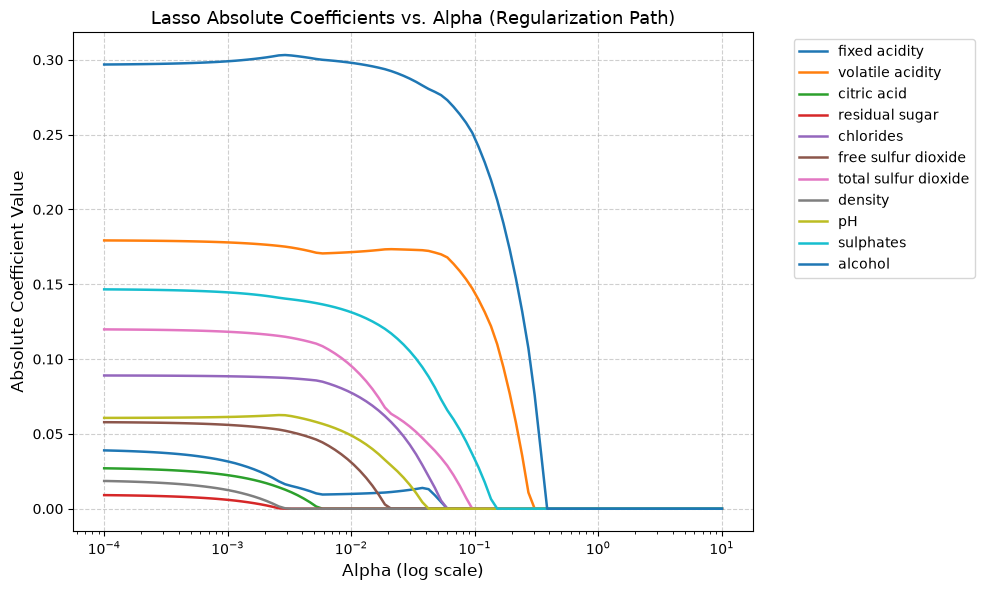

In [ ]:
# Continuous alpha range on log scale
alpha_range = np.logspace(-4, 1, 100)
coef_matrix = []

for a in alpha_range:
    lasso_model = Lasso(alpha=a, random_state=42)
    lasso_model.fit(X_train_scaled, y_train)
    coef_matrix.append(np.abs(lasso_model.coef_))

coef_matrix = np.array(coef_matrix)

# Plot absolute coefficient values against alpha
plt.figure(figsize=(10, 6))
for i, col in enumerate(X.columns):
    plt.plot(alpha_range, coef_matrix[:, i], label=col, linewidth=1.8)

plt.xscale("log")
plt.xlabel("Alpha (log scale)", fontsize=12)
plt.ylabel("Absolute Coefficient Value", fontsize=12)
plt.title("Lasso Absolute Coefficients vs. Alpha (Regularization Path)", fontsize=13)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
# As alpha increases, regularization becomes stronger and coefficients tend to shrink toward zero

## Cell 9: Identify Which Feature Reaches Zero First

In [9]:
# Identify smallest alpha where each feature coefficient reaches zero
first_zero_alpha = {}

for a in alpha_range:
    lasso_model = Lasso(alpha=a, random_state=42)
    lasso_model.fit(X_train_scaled, y_train)
    for feat, coef in zip(X.columns, lasso_model.coef_):
        if feat not in first_zero_alpha and np.isclose(coef, 0.0, atol=1e-5):
            first_zero_alpha[feat] = a

# Display summary table
zero_df = pd.DataFrame(
    list(first_zero_alpha.items()),
    columns=["Feature", "Alpha Reaching Zero"]
).sort_values("Alpha Reaching Zero").reset_index(drop=True)

print(zero_df)
first_feat = zero_df.iloc[0]["Feature"]
first_val = zero_df.iloc[0]["Alpha Reaching Zero"]
print(f"\nThe feature whose coefficient reaches zero first is: '{first_feat}' (at alpha ≈ {first_val:.4f}).")

                 Feature  Alpha Reaching Zero
0         residual sugar             0.002915
1                density             0.003275
2            citric acid             0.005857
3    free sulfur dioxide             0.021049
4                     pH             0.042292
5          fixed acidity             0.059948
6              chlorides             0.059948
7   total sulfur dioxide             0.095455
8              sulphates             0.151991
9       volatile acidity             0.305386
10               alcohol             0.385353

The feature whose coefficient reaches zero first is: 'residual sugar' (at alpha ≈ 0.0029).


# Question 6: Logistic Regression Classification

## Cell 10: Create Binary Quality Target

In [10]:
# Convert quality into binary target: Good wine (>= 7) vs Not good wine (< 7)
y_binary = (df["quality"] >= 7).astype(int)

print("Class distribution (0: Not good, 1: Good):")
print(y_binary.value_counts())
print(f"Percentage of good wines: {(y_binary.mean() * 100):.2f}%")

Class distribution (0: Not good, 1: Good):
quality
0    1382
1     217
Name: count, dtype: int64
Percentage of good wines: 13.57%


## Cell 11: Split and Standardize Classification Data

In [11]:
# Split into 80% train and 20% test with random_state=42
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

# Standardize features (fit only on training set)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

## Cell 12: Train Logistic Regression

In [12]:
# Fit Logistic Regression with max_iter=1000
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_c_scaled, y_train_c)

print("Logistic Regression training complete.")

Logistic Regression training complete.


## Cell 13: Calculate and Print Evaluation Metrics

In [15]:
# Predict on test set
y_pred_c = clf.predict(X_test_c_scaled)

# Calculate evaluation metrics
acc = accuracy_score(y_test_c, y_pred_c)
prec = precision_score(y_test_c, y_pred_c, zero_division=0)
rec = recall_score(y_test_c, y_pred_c, zero_division=0)
f1 = f1_score(y_test_c, y_pred_c, zero_division=0)

# Print metrics clearly
print(f"Accuracy:  {acc:.4f} ({acc * 100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec * 100:.2f}%)")
print(f"Recall:    {rec:.4f} ({rec * 100:.2f}%)")
print(f"F1-score:  {f1:.4f} ({f1 * 100:.2f}%)")


Accuracy:  0.8656 (86.56%)
Precision: 0.5909 (59.09%)
Recall:    0.2766 (27.66%)
F1-score:  0.3768 (37.68%)


## Cell 14: Conclusion

### Question 5 Findings:
1. **Model Comparison:** For small alpha values ($\alpha = 0.001, 0.01$), Ridge, Lasso, and ElasticNet achieve virtually identical test RMSE ($\approx 0.6245$). As alpha increases to $1$ and $10$, Lasso and ElasticNet aggressively zero out all feature coefficients, resulting in baseline dummy prediction error ($\text{RMSE} \approx 0.8107$). In contrast, Ridge shrinks coefficients continuously without zeroing them, maintaining a steady test RMSE ($\approx 0.6246$).
2. **Feature Sparsity:** Under Lasso regularization, **residual sugar** is the very first feature whose coefficient reaches zero (at $\alpha \approx 0.0027$), followed closely by `density` and `citric acid`. Meanwhile, `alcohol`, `volatile acidity`, and `sulphates` retain strong predictive weights longest.

### Question 6 Findings:
1. **Classification Performance:** The standardized Logistic Regression classifier achieves an overall accuracy of **86.56%**, with precision of **59.09%**, recall of **27.66%**, and F1-score of **37.68%**.
2. **Class Imbalance Effect:** Only $13.57\%$ of wines in the dataset belong to the 'good' class (quality $\ge 7$). This severe class skew allows the model to attain high accuracy by mostly predicting the majority negative class, while exhibiting a lower recall for minority positive instances.